# Understand how the four market sectors respond to the 10 strongest us landfall hurricanes

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hurricane_df = pd.read_csv(
    "../../data/disaster_data/us_landfall_hurricanes_hurdat.csv"
)

market_df = pd.read_csv(
    "../../data/stock_data/market_raw.csv"
)

hurricane_df["landfall_time"] = pd.to_datetime(
    hurricane_df["landfall_time"]
)

market_df["Date"] = pd.to_datetime(market_df["Date"])

market_df = (
    market_df
    .sort_values("Date")
    .drop_duplicates(subset="Date")
    .reset_index(drop=True)
)

print("Hurricanes:", hurricane_df.shape)
print("Market observations:", market_df.shape)

Hurricanes: (46, 21)
Market observations: (6538, 31)


## Identify the ten strongest hurricanes

In [22]:


N = 10

top_n = (
    hurricane_df
    .dropna(subset=[
        "landfall_wind_kts",
        "landfall_time"
    ])
    .sort_values(
        by=[
            "landfall_wind_kts",
            "landfall_pressure_mb",
            "storm_id"
        ],
        ascending=[False, True, True]
    )
    .head(N)
    .copy()
)

display(top_n[
    [
        "hurricane_name",
        "season",
        "landfall_wind_kts",
        "landfall_pressure_mb",
        "landfall_time"
    ]
])

,hurricane_name,season,landfall_wind_kts,landfall_pressure_mb,landfall_time
27,Michael (2018),2018,140.0,919.0,2018-10-10 17:30:00
36,Ida (2021),2021,130.0,931.0,2021-08-29 16:55:00
32,Laura (2020),2020,130.0,939.0,2020-08-27 06:00:00
3,Charley (2004),2004,130.0,941.0,2004-08-13 19:45:00
38,Ian (2022),2022,130.0,941.0,2022-09-28 19:05:00
44,Helene (2024),2024,120.0,939.0,2024-09-27 03:10:00
24,Irma (2017),2017,115.0,931.0,2017-09-10 13:00:00
23,Harvey (2017),2017,115.0,937.0,2017-08-26 03:00:00
10,Katrina (2005),2005,110.0,920.0,2005-08-29 11:10:00
6,Ivan (2004),2004,105.0,946.0,2004-09-16 06:50:00


## Calculate daily returns

In [23]:
tickers = ["SPY", "XLE", "XLF", "XLI", "XLU"]

sectors = ["XLE", "XLF", "XLI", "XLU"]

sector_names = {
    "XLE": "Energy",
    "XLF": "Financials",
    "XLI": "Industrials",
    "XLU": "Utilities"
}

for ticker in tickers:
    market_df[f"{ticker}_Return"] = (
        market_df[f"{ticker}_Close"]
        .pct_change(fill_method=None) * 100
    )

display(market_df[
    ["Date"] + [f"{t}_Return" for t in tickers]
].head(10))

,Date,SPY_Return,XLE_Return,XLF_Return,XLI_Return,XLU_Return
0,1999-11-24,NaN,NaN,NaN,NaN,NaN
1,1999-11-26,-0.374233,-1.469005,-0.693181,-0.498093,1.147644
2,1999-11-29,-0.353478,-0.802693,-2.411130,-1.668545,-1.134623
3,1999-11-30,-1.175169,-0.173430,1.690458,-0.452494,1.256923
4,1999-12-01,0.807698,1.968708,-0.767216,0.795425,0.485652
5,1999-12-02,0.600974,-0.965377,0.450945,-0.225493,-0.590705
6,1999-12-03,1.836264,-0.458675,2.373393,1.638429,1.944881
7,1999-12-06,-0.738668,-0.057603,-2.694194,-0.277895,-0.688954
8,1999-12-07,-0.809757,-1.901980,-0.193254,-1.895211,0.747102
9,1999-12-08,-0.639944,1.057494,-2.387051,1.761381,-0.794485


## Calculate abnormal returns by using SPY as the baseline

In [24]:
for sector in sectors:
    market_df[f"{sector}_AR"] = (
        market_df[f"{sector}_Return"]
        - market_df["SPY_Return"]
    )

display(market_df[
    ["Date"] + [f"{s}_AR" for s in sectors]
].head(10))

,Date,XLE_AR,XLF_AR,XLI_AR,XLU_AR
0,1999-11-24,NaN,NaN,NaN,NaN
1,1999-11-26,-1.094772,-0.318948,-0.123859,1.521878
2,1999-11-29,-0.449215,-2.057651,-1.315066,-0.781145
3,1999-11-30,1.001739,2.865627,0.722675,2.432092
4,1999-12-01,1.161010,-1.574914,-0.012273,-0.322046
5,1999-12-02,-1.566351,-0.150029,-0.826467,-1.191679
6,1999-12-03,-2.294939,0.537129,-0.197835,0.108617
7,1999-12-06,0.681065,-1.955526,0.460774,0.049714
8,1999-12-07,-1.092223,0.616503,-1.085454,1.556859
9,1999-12-08,1.697438,-1.747106,2.401326,-0.154541


In [25]:
trading_dates = pd.DatetimeIndex(market_df["Date"])

def get_event_date(landfall_time):

    if pd.isna(landfall_time):
        return pd.NaT

    landfall_date = landfall_time.normalize()

    idx = trading_dates.searchsorted(
        landfall_date,
        side="left"
    )

    if idx >= len(trading_dates):
        return pd.NaT

    return trading_dates[idx]


top_n["event_date"] = (
    top_n["landfall_time"]
    .apply(get_event_date)
)

display(top_n[
    [
        "hurricane_name",
        "landfall_time",
        "event_date"
    ]
])

,hurricane_name,landfall_time,event_date
27,Michael (2018),2018-10-10 17:30:00,2018-10-10
36,Ida (2021),2021-08-29 16:55:00,2021-08-30
32,Laura (2020),2020-08-27 06:00:00,2020-08-27
3,Charley (2004),2004-08-13 19:45:00,2004-08-13
38,Ian (2022),2022-09-28 19:05:00,2022-09-28
44,Helene (2024),2024-09-27 03:10:00,2024-09-27
24,Irma (2017),2017-09-10 13:00:00,2017-09-11
23,Harvey (2017),2017-08-26 03:00:00,2017-08-28
10,Katrina (2005),2005-08-29 11:10:00,2005-08-29
6,Ivan (2004),2004-09-16 06:50:00,2004-09-16


## Create event study dataset

In [26]:
event_rows = []

for _, storm in top_n.iterrows():

    event_date = storm["event_date"]

    if pd.isna(event_date):
        continue

    matches = market_df.index[
        market_df["Date"] == event_date
    ]

    if len(matches) == 0:
        continue

    event_idx = matches[0]

    # Require the complete event window
    if event_idx < 5 or event_idx + 14 >= len(market_df):
        continue

    window = market_df.iloc[
        event_idx - 5 : event_idx + 15
    ].copy()

    window["relative_day"] = np.arange(-5, 15)

    for sector in sectors:

        if window[f"{sector}_AR"].isna().any():
            continue

        for _, row in window.iterrows():

            event_rows.append({
                "storm_id": storm["storm_id"],
                "hurricane": storm["hurricane_name"],
                "year": storm["season"],
                "sector": sector,
                "Date": row["Date"],
                "relative_day": row["relative_day"],
                "AR": row[f"{sector}_AR"]
            })

event_study = pd.DataFrame(event_rows)

event_study = event_study.sort_values(
    ["storm_id", "sector", "relative_day"]
)

event_study["CAR"] = (
    event_study
    .groupby(["storm_id", "sector"])["AR"]
    .cumsum()
)

display(event_study.head(10))

,storm_id,hurricane,year,sector,Date,relative_day,AR,CAR
240,2004223N11301,Charley (2004),2004,XLE,2004-08-06,-5,-0.566321,-0.566321
241,2004223N11301,Charley (2004),2004,XLE,2004-08-09,-4,1.476136,0.909815
242,2004223N11301,Charley (2004),2004,XLE,2004-08-10,-3,-1.671501,-0.761686
243,2004223N11301,Charley (2004),2004,XLE,2004-08-11,-2,-0.307998,-1.069684
244,2004223N11301,Charley (2004),2004,XLE,2004-08-12,-1,-0.193080,-1.262764
245,2004223N11301,Charley (2004),2004,XLE,2004-08-13,0,1.039401,-0.223364
246,2004223N11301,Charley (2004),2004,XLE,2004-08-16,1,-0.425179,-0.648543
247,2004223N11301,Charley (2004),2004,XLE,2004-08-17,2,-2.862130,-3.510673
248,2004223N11301,Charley (2004),2004,XLE,2004-08-18,3,0.278797,-3.231876
249,2004223N11301,Charley (2004),2004,XLE,2004-08-19,4,0.613456,-2.618421


## Calculate CAR for three windows

In [27]:
windows = {
    "0_to_1": (0, 1),
    "0_to_5": (0, 5),
    "0_to_14": (0, 14)
}

car_rows = []

for (storm_id, sector), group in event_study.groupby(
    ["storm_id", "sector"]
):

    for window_name, (start, end) in windows.items():

        selected = group[
            group["relative_day"].between(start, end)
        ]

        if len(selected) != end - start + 1:
            continue

        car_rows.append({
            "storm_id": storm_id,
            "hurricane": group["hurricane"].iloc[0],
            "year": group["year"].iloc[0],
            "sector": sector,
            "window": window_name,
            "CAR": selected["AR"].sum()
        })

car_df = pd.DataFrame(car_rows)

display(car_df.head(12))

,storm_id,hurricane,year,sector,window,CAR
0,2004223N11301,Charley (2004),2004,XLE,0_to_1,0.614221
1,2004223N11301,Charley (2004),2004,XLE,0_to_5,-1.028575
2,2004223N11301,Charley (2004),2004,XLE,0_to_14,1.328395
3,2004223N11301,Charley (2004),2004,XLF,0_to_1,0.403979
4,2004223N11301,Charley (2004),2004,XLF,0_to_5,0.786949
5,2004223N11301,Charley (2004),2004,XLF,0_to_14,0.603063
6,2004223N11301,Charley (2004),2004,XLI,0_to_1,0.451366
7,2004223N11301,Charley (2004),2004,XLI,0_to_5,-0.250132
8,2004223N11301,Charley (2004),2004,XLI,0_to_14,0.304730
9,2004223N11301,Charley (2004),2004,XLU,0_to_1,-1.148785


## CAR heatmap

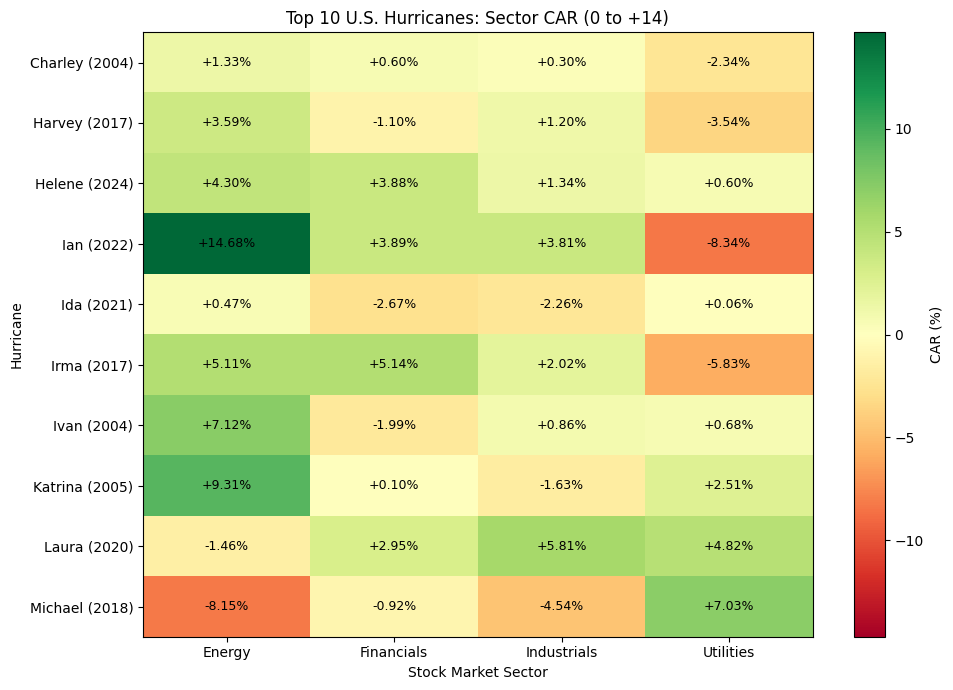

In [28]:
heatmap = (
    car_df[car_df["window"] == "0_to_14"]
    .pivot(
        index="hurricane",
        columns="sector",
        values="CAR"
    )
)

heatmap = heatmap.rename(columns=sector_names)

fig, ax = plt.subplots(figsize=(10, 7))

values = heatmap.to_numpy()

limit = max(np.nanmax(np.abs(values)), 0.01)

im = ax.imshow(
    values,
    cmap="RdYlGn",
    vmin=-limit,
    vmax=limit,
    aspect="auto"
)

ax.set_xticks(range(len(heatmap.columns)))
ax.set_xticklabels(heatmap.columns)

ax.set_yticks(range(len(heatmap.index)))
ax.set_yticklabels(heatmap.index)

for i in range(len(heatmap.index)):
    for j in range(len(heatmap.columns)):
        ax.text(
            j, i,
            f"{values[i, j]:+.2f}%",
            ha="center",
            va="center",
            fontsize=9
        )

fig.colorbar(im, ax=ax, label="CAR (%)")

ax.set_title(
    "Top 10 U.S. Hurricanes: Sector CAR (0 to +14)"
)

ax.set_xlabel("Stock Market Sector")
ax.set_ylabel("Hurricane")

plt.tight_layout()
plt.show()

## Plot cumulative abnormal returns over time

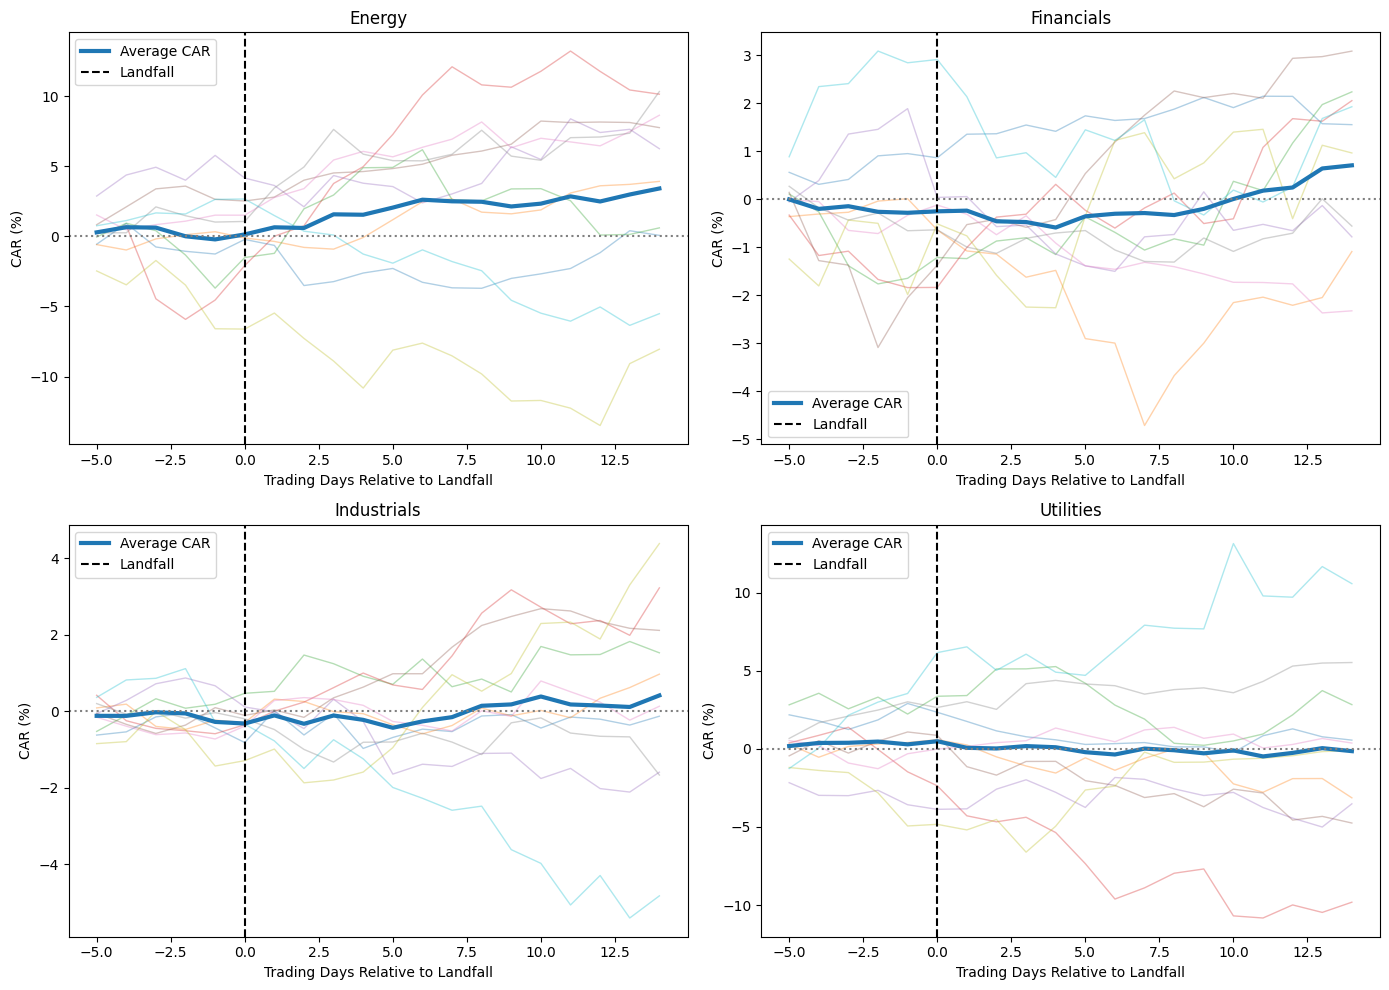

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, sector in zip(axes.flat, sectors):

    data = event_study[
        event_study["sector"] == sector
    ]

    for hurricane, group in data.groupby("hurricane"):
        ax.plot(
            group["relative_day"],
            group["CAR"],
            linewidth=1,
            alpha=0.35
        )

    average = (
        data.groupby("relative_day")["CAR"]
        .mean()
    )

    ax.plot(
        average.index,
        average.values,
        linewidth=3,
        label="Average CAR"
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        label="Landfall"
    )

    ax.axhline(
        0,
        color="gray",
        linestyle=":"
    )

    ax.set_title(sector_names[sector])
    ax.set_xlabel("Trading Days Relative to Landfall")
    ax.set_ylabel("CAR (%)")
    ax.legend()

plt.tight_layout()
plt.show()

## Calculate average CAR and direction counts

In [31]:
summary = (
    car_df
    .groupby(["sector", "window"])
    .agg(
        mean_car=("CAR", "mean"),
        median_car=("CAR", "median"),
        positive_count=(
            "CAR",
            lambda x: (x > 0).sum()
        ),
        negative_count=(
            "CAR",
            lambda x: (x < 0).sum()
        ),
        total_storms=("CAR", "count")
    )
    .reset_index()
)

summary["sector"] = summary["sector"].replace(
    sector_names
)

display(summary)

,sector,window,mean_car,median_car,positive_count,negative_count,total_storms
0,Energy,0_to_1,0.862607,0.866635,7,3,10
1,Energy,0_to_14,3.630072,3.943028,8,2,10
2,Energy,0_to_5,2.267830,1.525119,6,4,10
3,Financials,0_to_1,0.044838,0.212429,6,4,10
4,Financials,0_to_14,0.988605,0.349967,6,4,10
5,Financials,0_to_5,-0.073571,0.395385,6,4,10
6,Industrials,0_to_1,0.169910,0.390694,6,4,10
7,Industrials,0_to_14,0.691696,1.028058,7,3,10
8,Industrials,0_to_5,-0.153467,0.168671,5,5,10
9,Utilities,0_to_1,-0.221130,-0.203395,4,6,10


## Visualize average CAR by sector and window

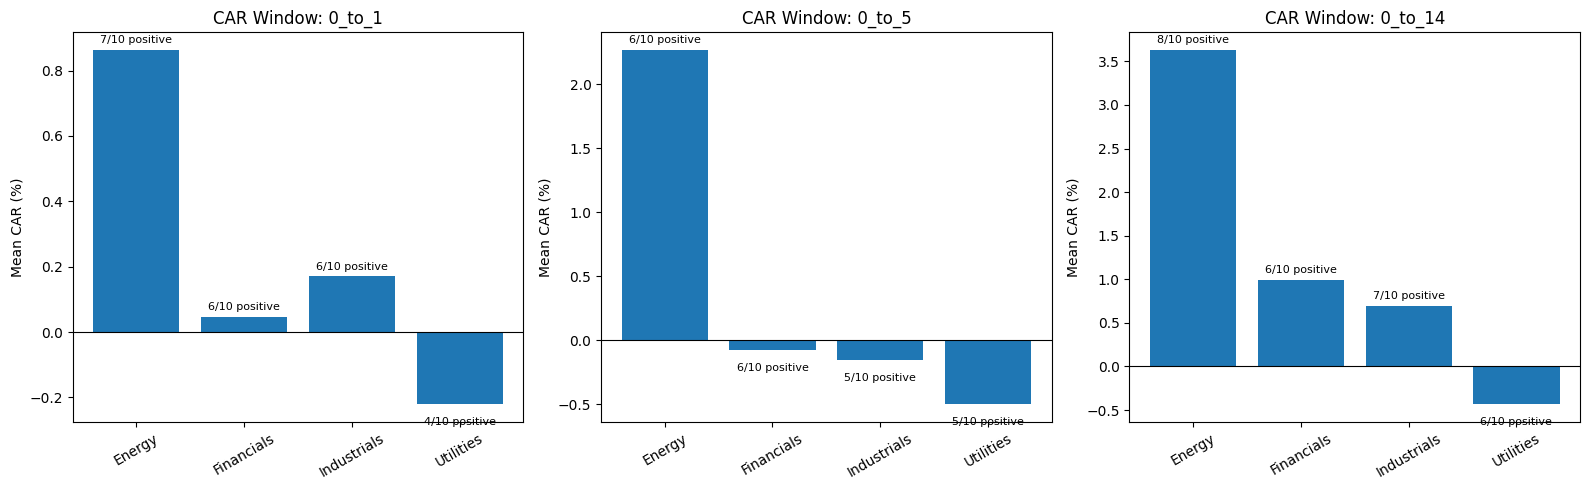

In [32]:
window_order = ["0_to_1", "0_to_5", "0_to_14"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, window_name in zip(axes, window_order):

    group = summary[
        summary["window"] == window_name
    ]

    bars = ax.bar(
        group["sector"],
        group["mean_car"]
    )

    for bar, (_, row) in zip(bars, group.iterrows()):

        height = bar.get_height()

        ax.annotate(
            f"{int(row['positive_count'])}/{int(row['total_storms'])} positive",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(
                0,
                5 if height >= 0 else -15
            ),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax.axhline(0, color="black", linewidth=0.8)

    ax.set_title(f"CAR Window: {window_name}")
    ax.set_ylabel("Mean CAR (%)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Check if COVID had any influence on this analysis

In [34]:
summary_without_2020 = (
    car_df[car_df["year"] != 2020]
    .groupby(["sector", "window"])["CAR"]
    .mean()
    .reset_index(name="mean_car_without_2020")
)

comparison = (
    car_df
    .groupby(["sector", "window"])["CAR"]
    .mean()
    .reset_index(name="mean_car")
    .merge(
        summary_without_2020,
        on=["sector", "window"],
        how="left"
    )
)

comparison["sector"] = comparison["sector"].replace(
    sector_names
)

display(comparison)

,sector,window,mean_car,mean_car_without_2020
0,Energy,0_to_1,0.862607,0.834113
1,Energy,0_to_14,3.630072,4.195426
2,Energy,0_to_5,2.267830,2.689209
3,Financials,0_to_1,0.044838,-0.085972
4,Financials,0_to_14,0.988605,0.770745
5,Financials,0_to_5,-0.073571,-0.263571
6,Industrials,0_to_1,0.169910,0.139508
7,Industrials,0_to_14,0.691696,0.122843
8,Industrials,0_to_5,-0.153467,-0.223952
9,Utilities,0_to_1,-0.221130,-0.217661
